In [ ]:
#Task 1: Features and label for the Spotify Top 50 dataset
import pandas as pd

df = pd.read_csv("top50.csv", encoding="latin-1")
print(df.columns)

# we want to predict the popularity score, so Popularity is the label
label = "Popularity"

# these describe how the song sounds, so they are the features
features = ["Beats.Per.Minute", "Energy", "Danceability", "Loudness..dB..", "Liveness",
            "Valence.", "Length.", "Acousticness..", "Speechiness."]

# Unnamed: 0 is just a row number, Track.Name and Artist.Name only identify the song
# so they are not used. Genre can also be used after converting it to numbers.
print("Label:", label)
print("Features:", features)

In [ ]:
#Task 2: Split the data into 80% training and 20% test
from sklearn.model_selection import train_test_split

x = df[features]
y = df[label]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Rows in training set:", len(x_train))
print("Rows in test set:", len(x_test))

In [ ]:
#Task 3: Linear regression on danceability with only 5% training data
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

x = df[["Danceability"]]
y = df["Popularity"]

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.05, random_state=1)
print("Rows in training set:", len(x_train))
print("Rows in test set:", len(x_test))

model = LinearRegression()
model.fit(x_train, y_train)

print("Train error:", mean_squared_error(y_train, model.predict(x_train)))
print("Test error:", mean_squared_error(y_test, model.predict(x_test)))

With only 5% of the data, the model gets just 2 rows for training. A straight line fits 2 points exactly, so the train error is 0, which looks perfect. But the test error is much higher. A very low train error with a much higher test error means overfitting. The model memorised the 2 training songs instead of learning the real pattern between danceability and popularity. It is not underfitting, because underfitting would show bad results on both train and test.

### Task 4: Bias-variance tradeoff graph and Zomato note

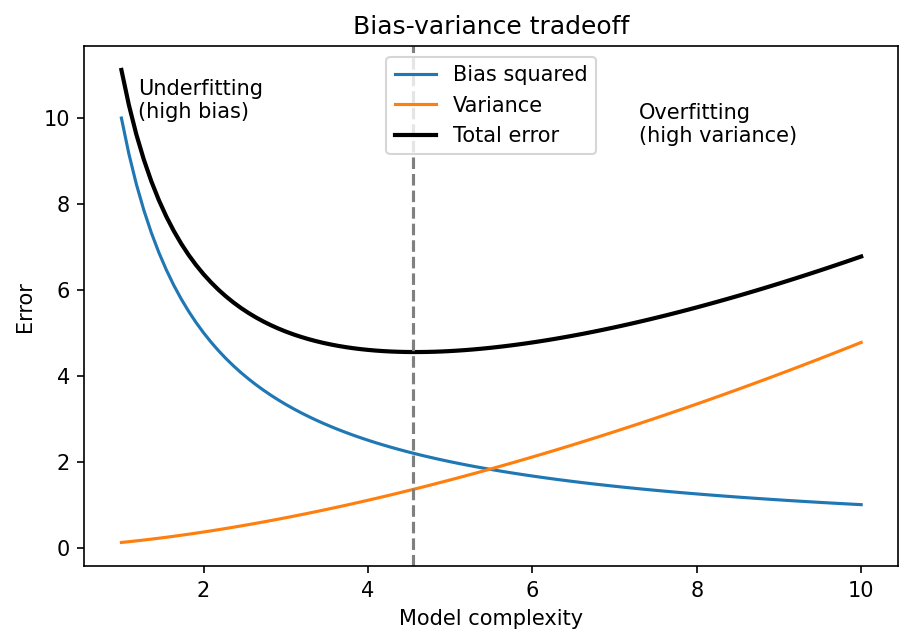

If the model is too simple (high bias), it will give almost the same rating to every restaurant and ignore things like cuisine, price and location. It underfits, so its predictions are wrong for both old and new restaurants.

If the model is too complex (high variance), it will memorise the training restaurants. For example, if one restaurant got a few 5 star reviews from friends, the model will treat that as a real pattern. It looks very accurate on the data it has seen but gives wild and wrong ratings for new restaurants.

A good rating predictor needs a model in the middle, not too simple and not too complex, so that it gives reasonable ratings for restaurants it has never seen.

### Task 5: Overfitting example from an app

Swiggy delivery time prediction. If the model is too complex or trained on too little data, it can memorise special cases from the training orders, like one rainy day when every delivery was very late. Then it starts showing long delivery times on normal days too, because it learned that one day as a rule instead of the general pattern.